# Vem Subclasses, Over Time (Cell + Nucleus)

Same shared embedding again, restricted to the `vem_1uM` condition only,
with a kernel density overlay per subclass (dying, persisting, slow
proliferator, fast proliferator) at each frame.

Plots both embeddings `main.py` computes (UMAP and PHATE) every time
this notebook runs, no manual switch needed.

Requires `main.py` to have been run first.


In [1]:
import os
import sys

import matplotlib.pyplot as plt

# assumes Jupyter's cwd is this notebook's own directory
# (analyses/01_naive_vs_vem/notebooks/), so the analysis dir - and config.py -
# is one level up, and the repo root - where shared/ lives - is two more
# levels up from there
NOTEBOOK_DIR = os.getcwd()
ANALYSIS_DIR = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..'))
REPO_ROOT    = os.path.abspath(os.path.join(ANALYSIS_DIR, '..', '..'))
sys.path.insert(0, REPO_ROOT)
sys.path.insert(0, ANALYSIS_DIR)
import config

# config.py's OUTPUT_DIR/CAJAL_OUTPUT_DIR are relative to the analysis
# directory, not this notebook's own cwd - re-anchor them to an absolute
# path once, here
config.OUTPUT_DIR       = os.path.join(ANALYSIS_DIR, config.OUTPUT_DIR)
config.CAJAL_OUTPUT_DIR = os.path.join(ANALYSIS_DIR, config.CAJAL_OUTPUT_DIR)

from shared.load_data import load_full_dataset
from shared.density_plots import export_kde_by_frame

## Plot: embedding with per-subclass kernel density, vem only

For each embedding method, one PDF, one SVG per frame, written to
`output/plots/03_vem_subclasses_over_time/` (SVGs in their own `svgs/`
subfolder there).


In [2]:
SUBCLASS_COLORS = {
    'dying':       'tab:red',
    'persisting':  'tab:purple',
    'slow_prolif': 'tab:orange',
    'fast_prolif': 'tab:green',
}
NOTEBOOK_PLOTS_DIR = os.path.join(config.OUTPUT_DIR, 'plots', '03_vem_subclasses_over_time')
MODALITY_NAMES = {'cell': 'cell', 'nuc': 'nucleus'}

# KDE contour levels (level p encloses the densest (1-p) fraction of a
# group's mass - higher is tighter/closer to the peak) and bandwidth
# multiplier (above 1 smooths over sampling/distance-tie noise)
KDE_LEVELS     = (0.7, 0.8, 0.9)
KDE_BW_ADJUST  = 1

# main.py computes both of these for every modality - plot both every
# time this notebook runs, rather than picking just one
EMBEDDING_METHODS = ['umap', 'phate']


def process_modality(modality):
    '''
    For each embedding method, load this modality's embedding and
    metadata, restrict to the vem condition, and export a PDF and a
    per-frame SVG with a KDE contour per subclass.

    Inputs:
        modality: 'cell' or 'nuc'
    Outputs:
        vem_dfs: {embedding_method: the vem-only subset for this
                  modality and embedding method} (in-memory only)
    '''
    vem_dfs = {}
    for embedding_method in EMBEDDING_METHODS:
        df = load_full_dataset(config.CAJAL_OUTPUT_DIR, modality, embedding_method)
        vem_df = df[df['condition'] == config.VEM_CONDITION]
        print(f"[{modality}/{embedding_method}] {len(vem_df)} vem cells across "
              f"{vem_df['subclass'].nunique()} subclasses, {vem_df['frame'].nunique()} frames")

        export_kde_by_frame(vem_df, 'subclass', SUBCLASS_COLORS, NOTEBOOK_PLOTS_DIR,
                             f'{modality}_{embedding_method}', embedding_method.upper(),
                             title_prefix=f'{MODALITY_NAMES[modality]} morphology (subclasses)',
                             levels=KDE_LEVELS, bw_adjust=KDE_BW_ADJUST)
        vem_dfs[embedding_method] = vem_df

    return vem_dfs


## Run: cell morphology

[cell/umap] 24000 vem cells across 4 subclasses, 13 frames


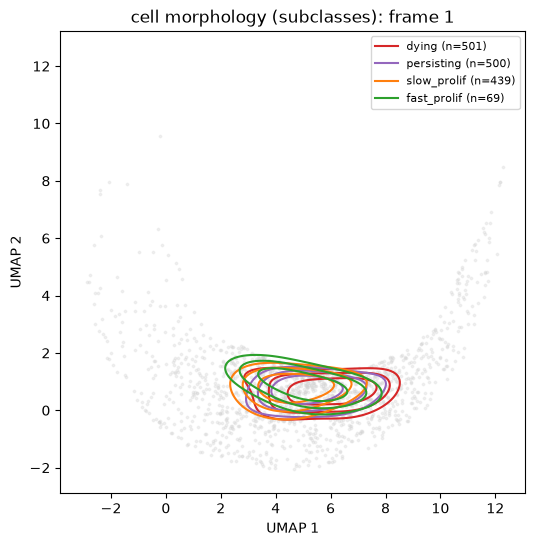

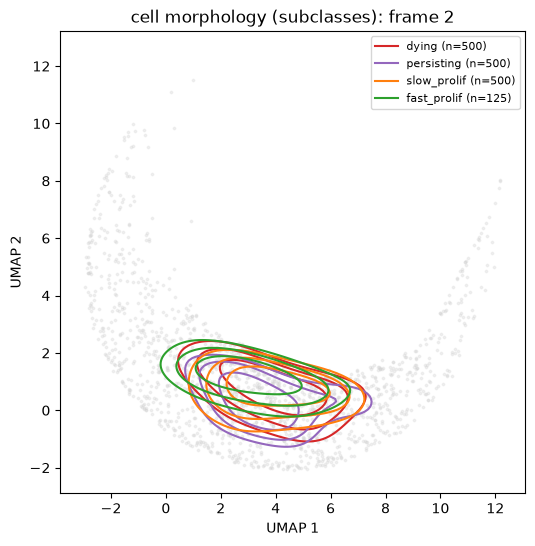

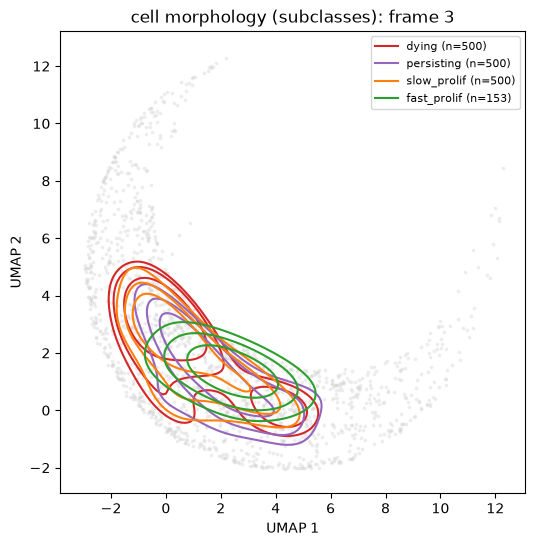

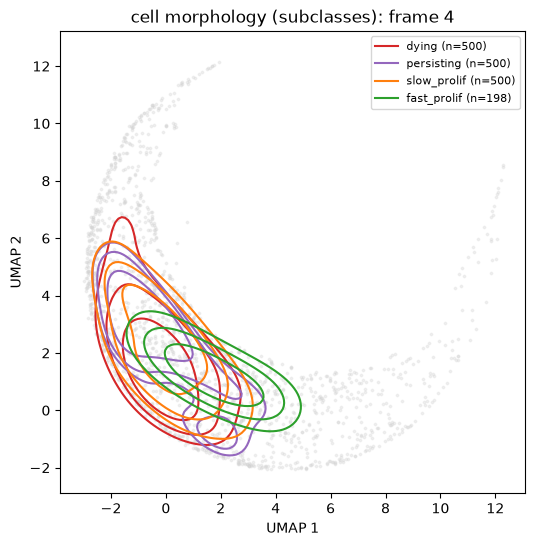

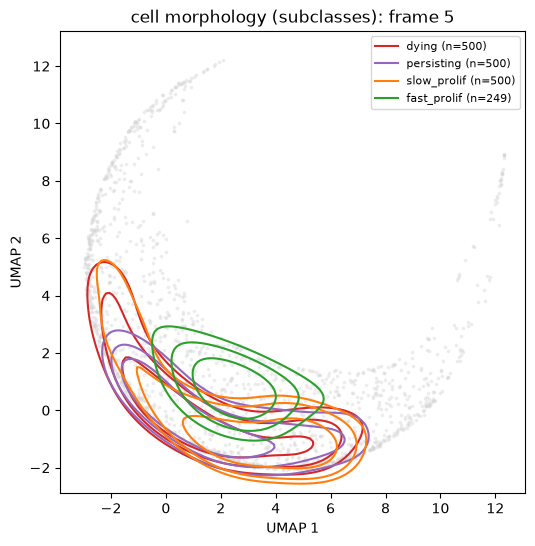

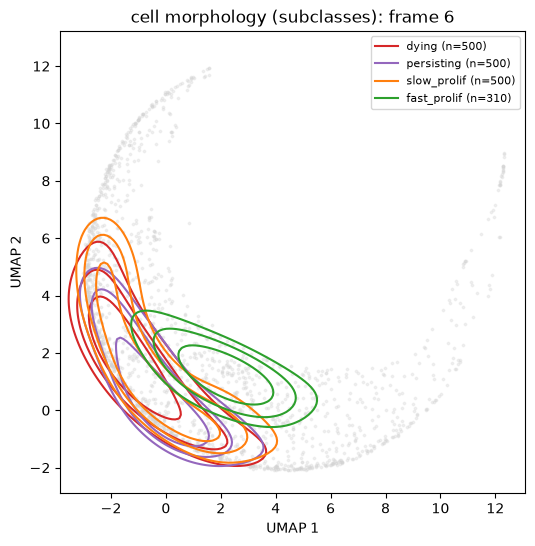

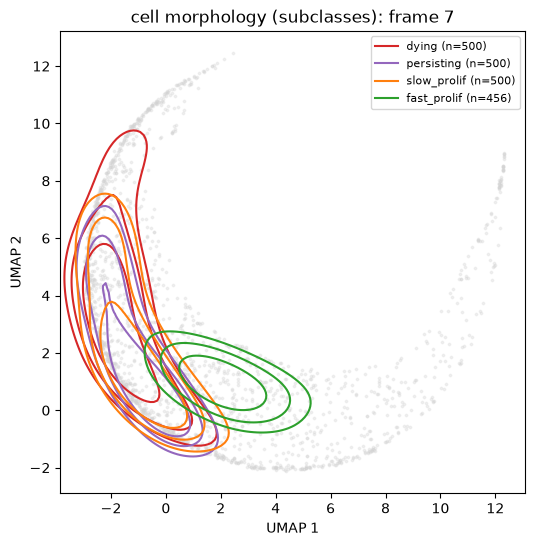

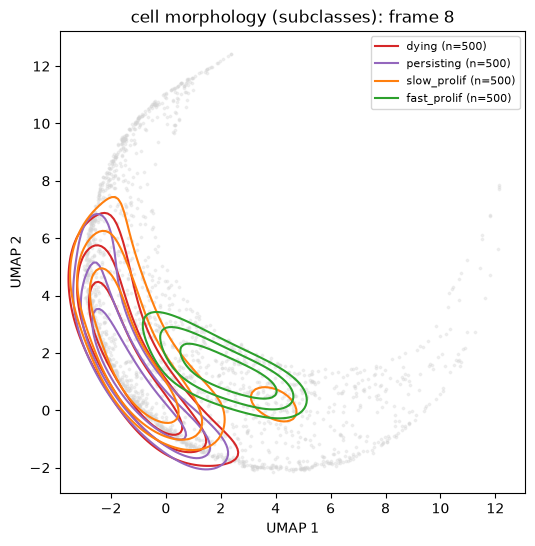

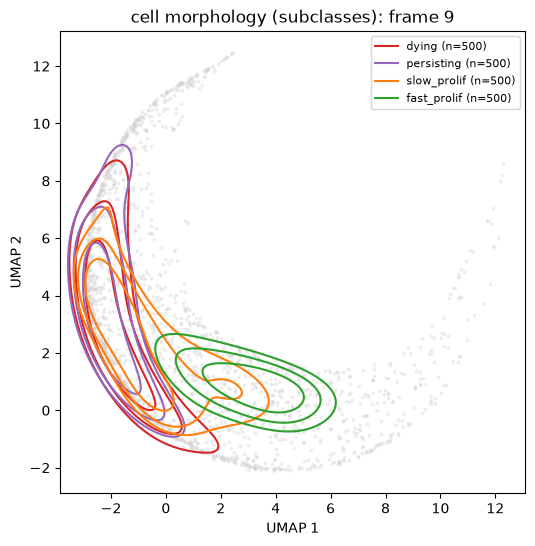

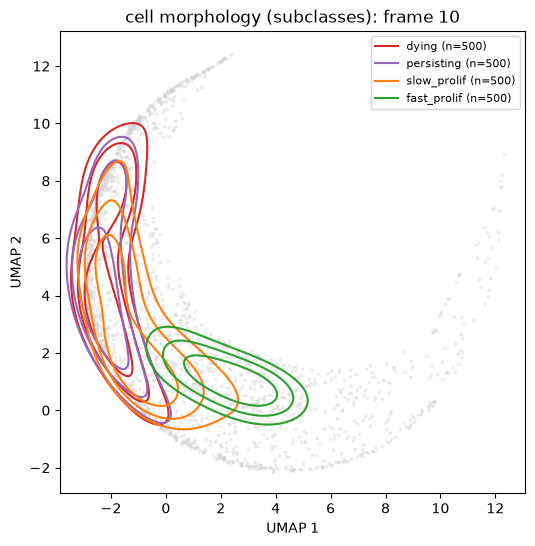

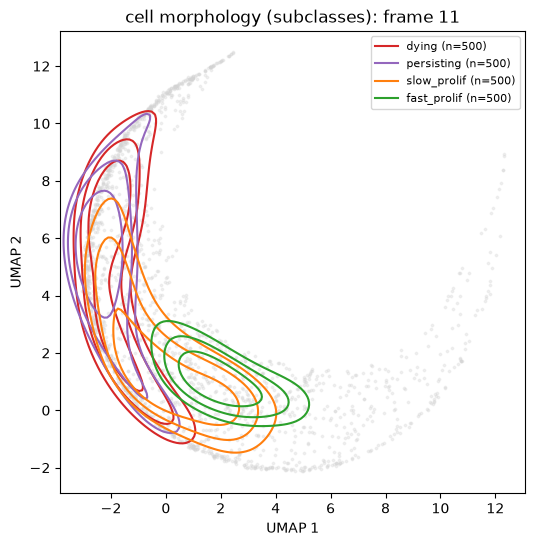

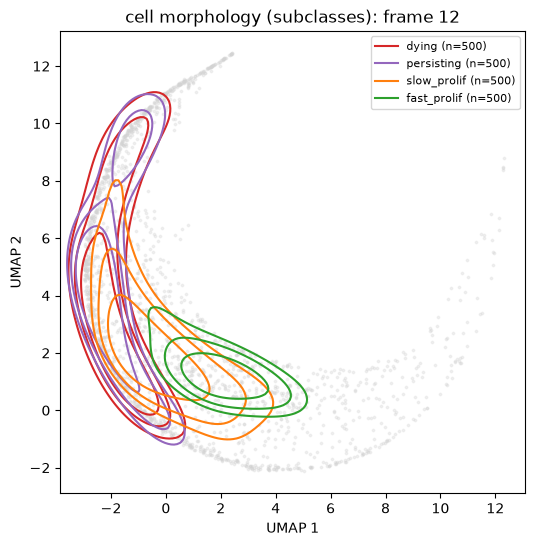

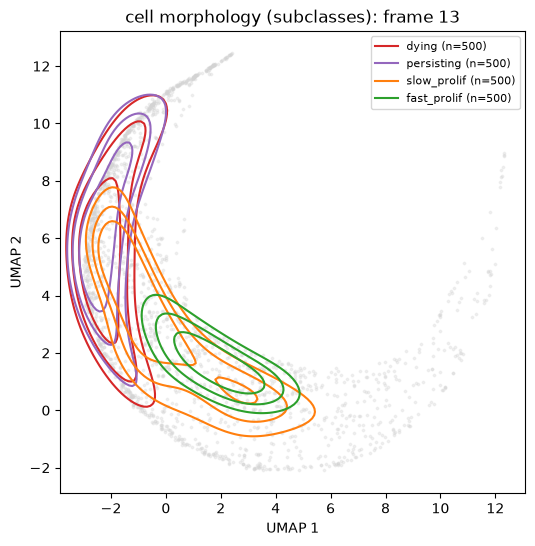

  Saved 13 frame(s) to /gpfs/projects/b1042/GoyalLab/sohini/drug_response_morphology/analyses/01_naive_vs_vem/output/plots/03_vem_subclasses_over_time/cell_umap.pdf and /gpfs/projects/b1042/GoyalLab/sohini/drug_response_morphology/analyses/01_naive_vs_vem/output/plots/03_vem_subclasses_over_time/svgs
[cell/phate] 24000 vem cells across 4 subclasses, 13 frames


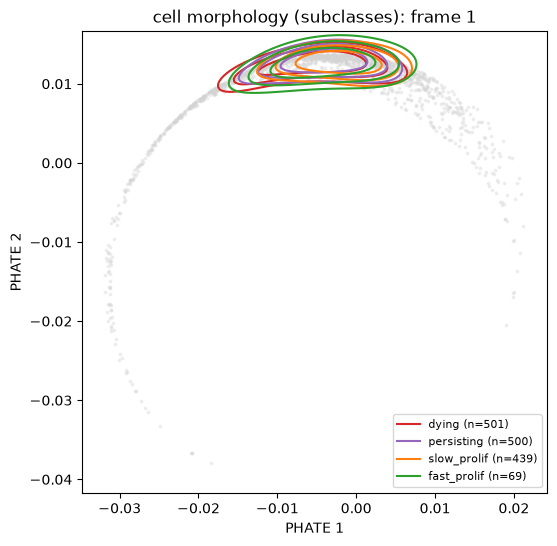

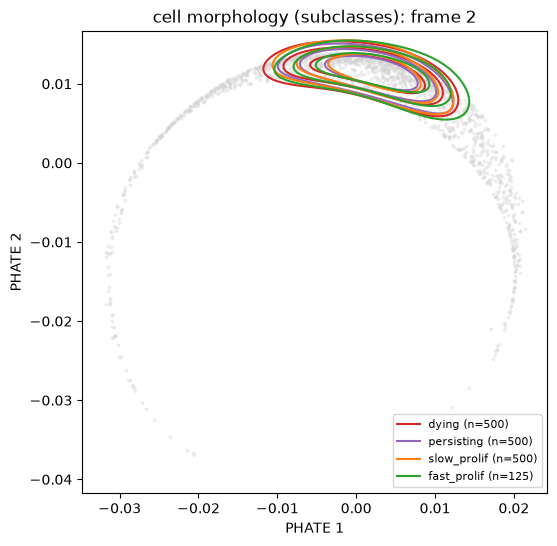

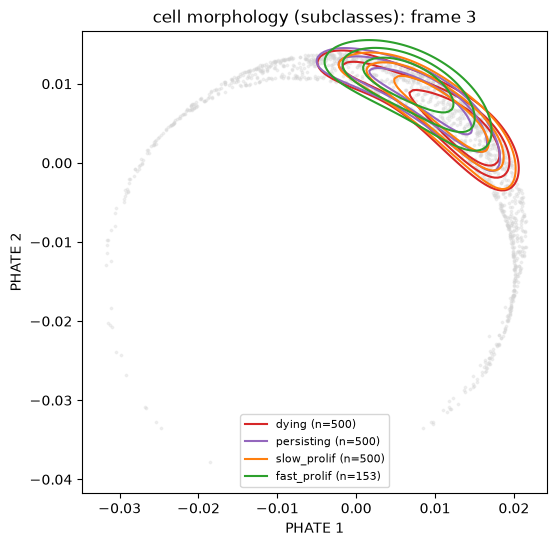

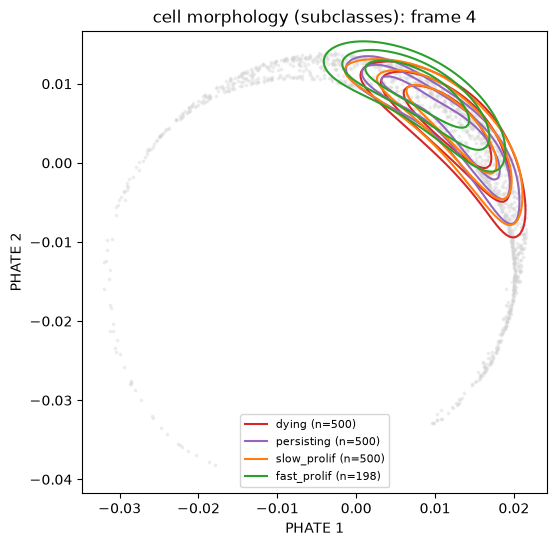

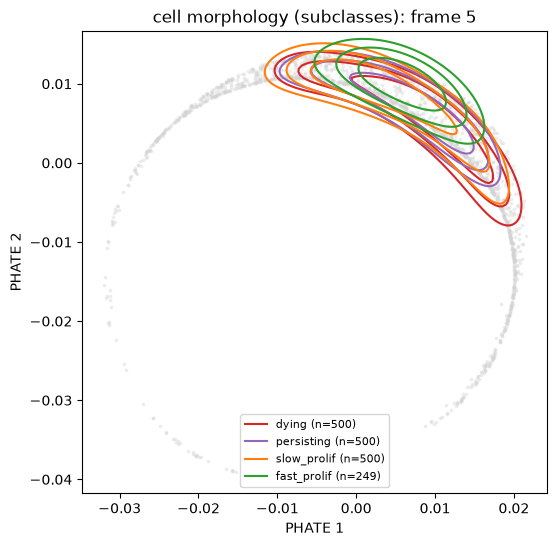

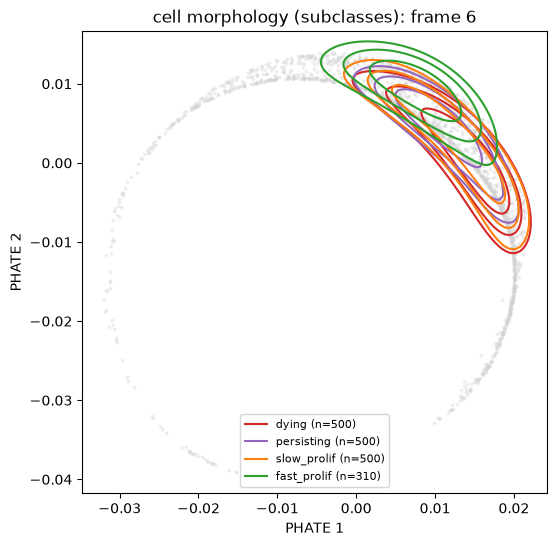

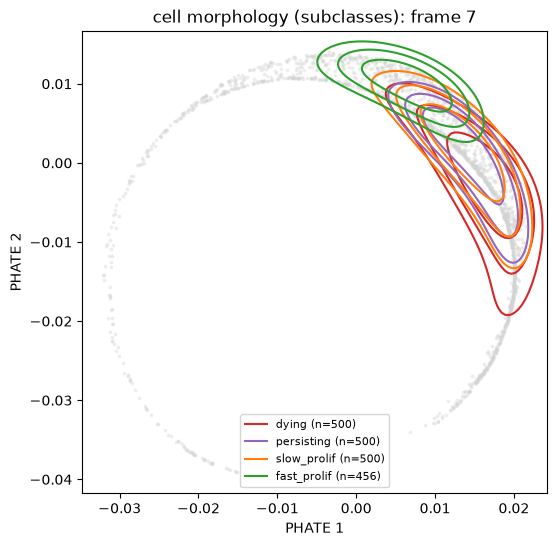

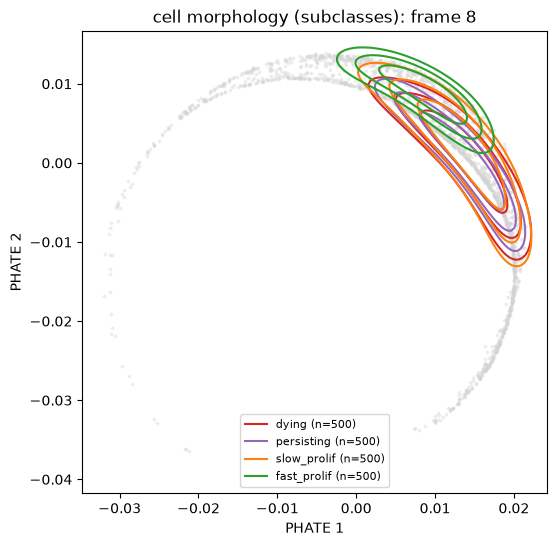

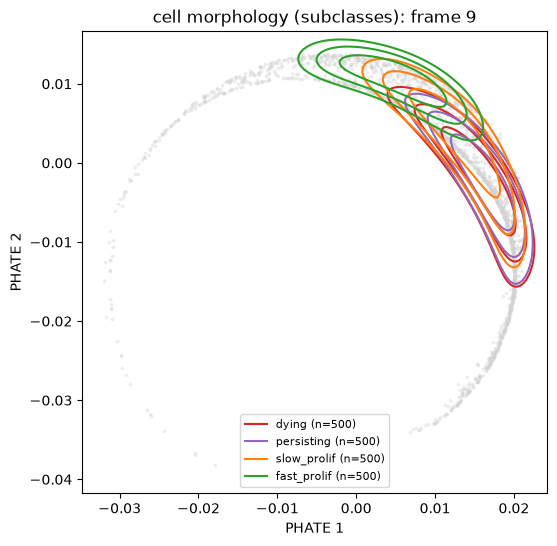

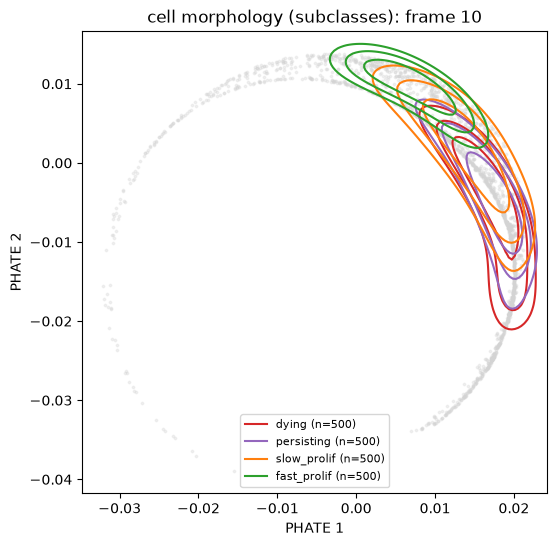

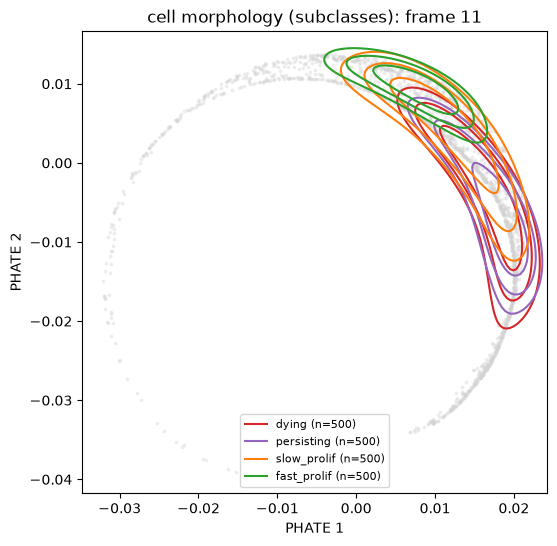

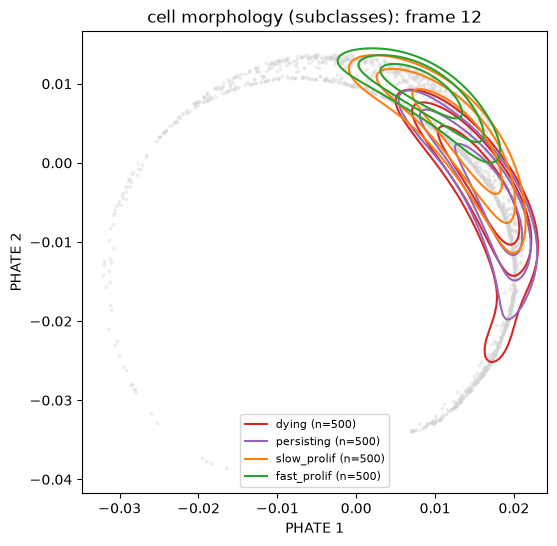

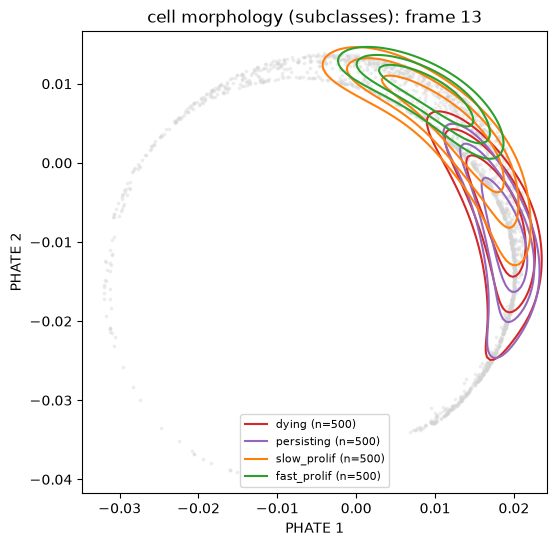

  Saved 13 frame(s) to /gpfs/projects/b1042/GoyalLab/sohini/drug_response_morphology/analyses/01_naive_vs_vem/output/plots/03_vem_subclasses_over_time/cell_phate.pdf and /gpfs/projects/b1042/GoyalLab/sohini/drug_response_morphology/analyses/01_naive_vs_vem/output/plots/03_vem_subclasses_over_time/svgs


In [3]:
cell_vem_dfs = process_modality('cell')


## Run: nuclear morphology

[nuc/umap] 24000 vem cells across 4 subclasses, 13 frames


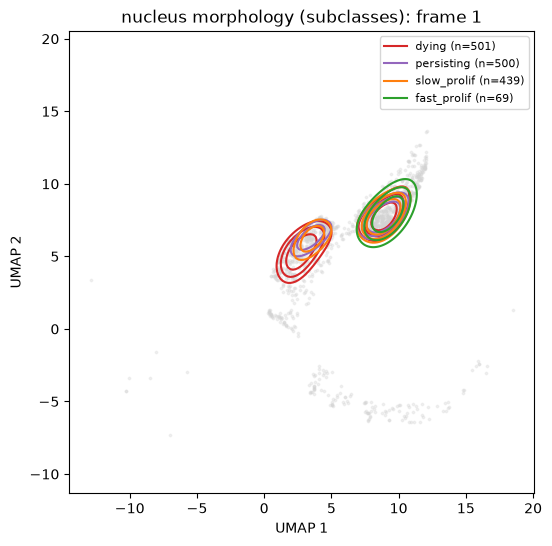

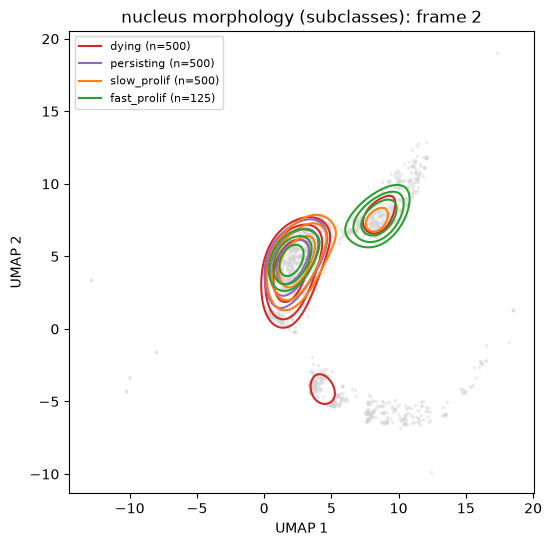

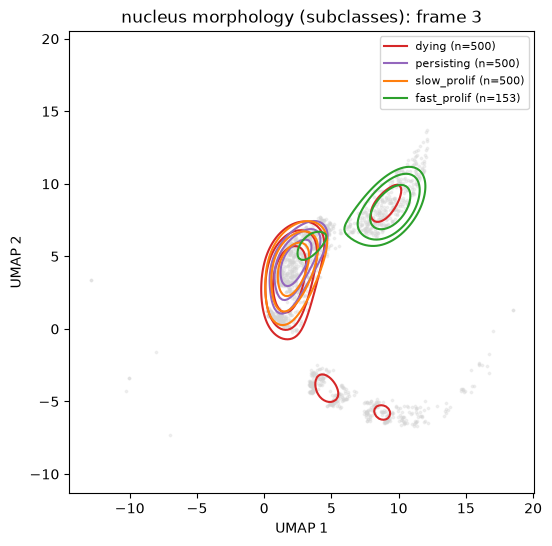

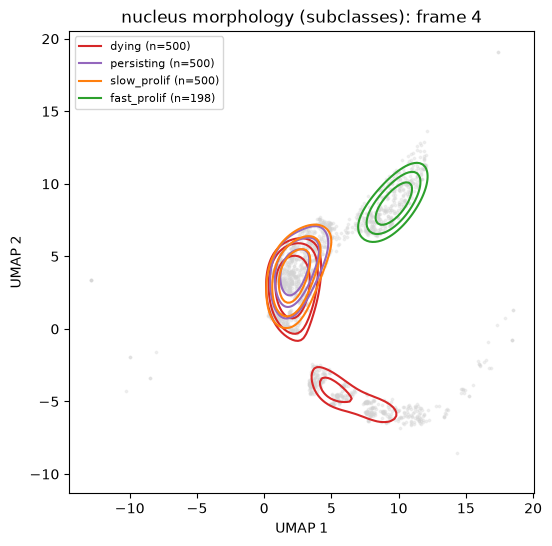

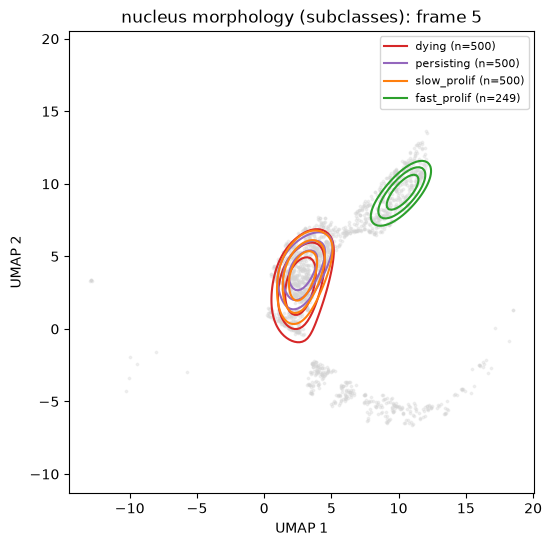

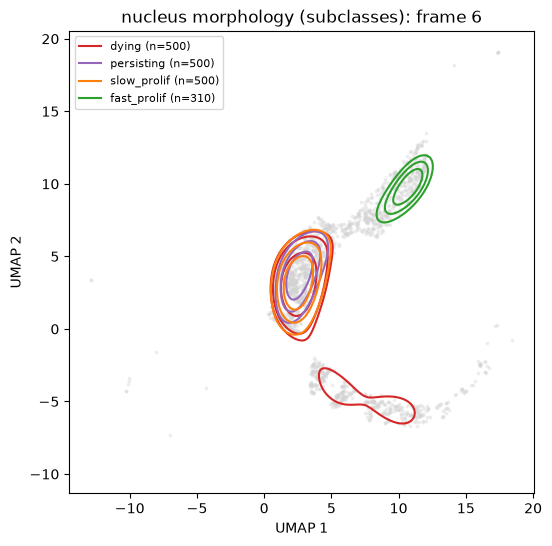

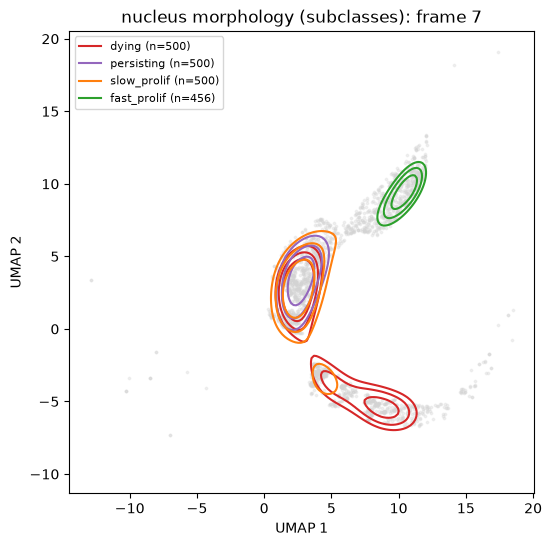

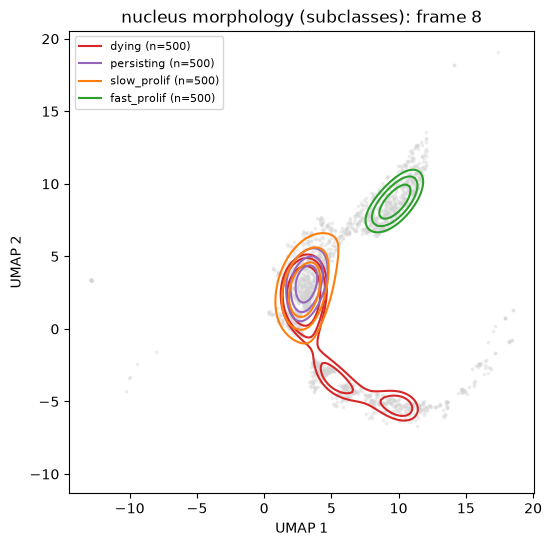

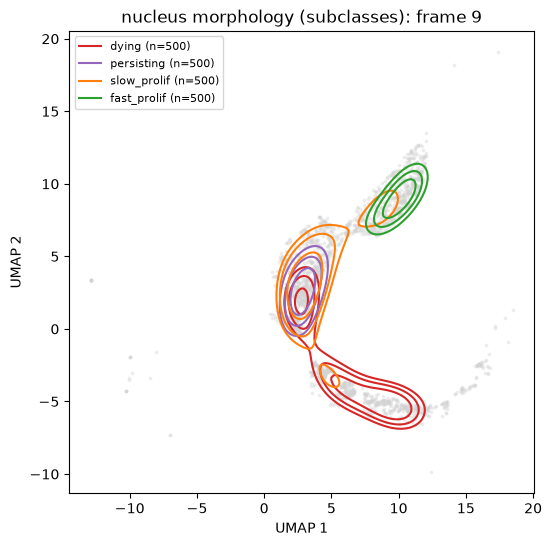

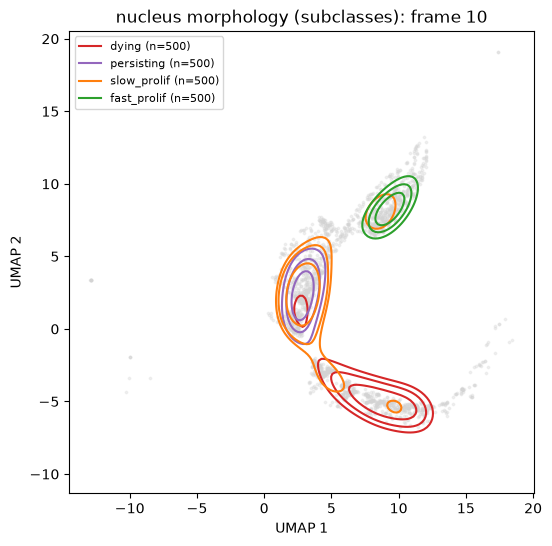

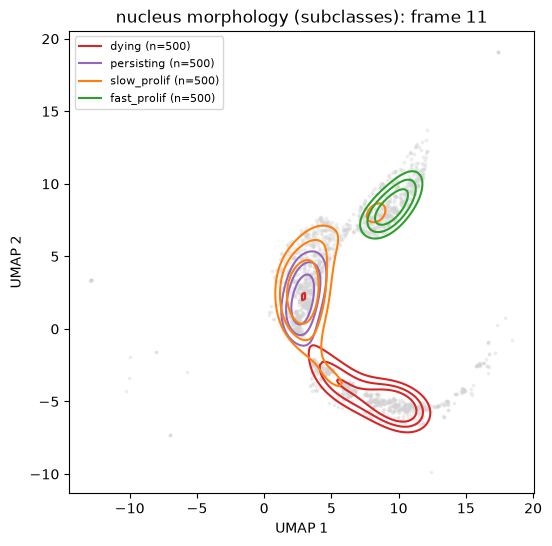

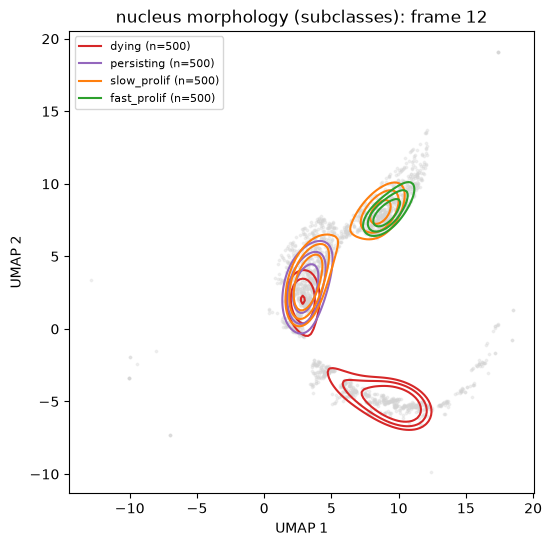

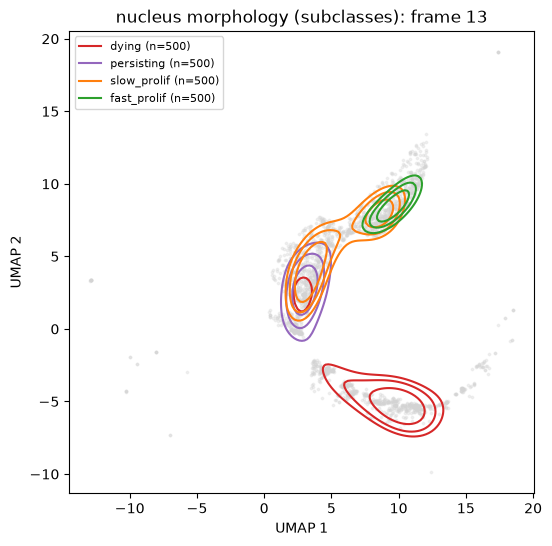

  Saved 13 frame(s) to /gpfs/projects/b1042/GoyalLab/sohini/drug_response_morphology/analyses/01_naive_vs_vem/output/plots/03_vem_subclasses_over_time/nuc_umap.pdf and /gpfs/projects/b1042/GoyalLab/sohini/drug_response_morphology/analyses/01_naive_vs_vem/output/plots/03_vem_subclasses_over_time/svgs
[nuc/phate] 24000 vem cells across 4 subclasses, 13 frames


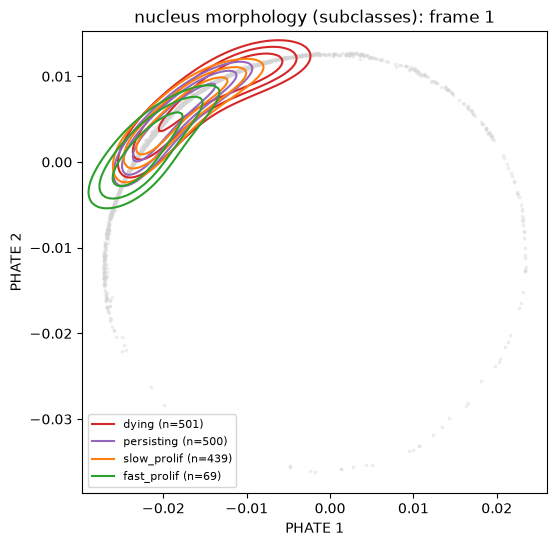

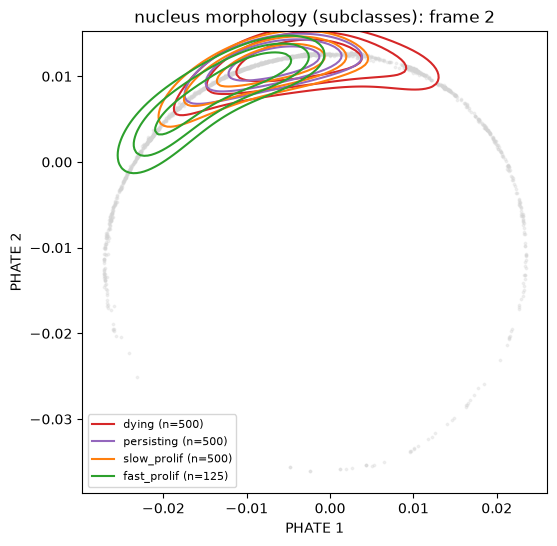

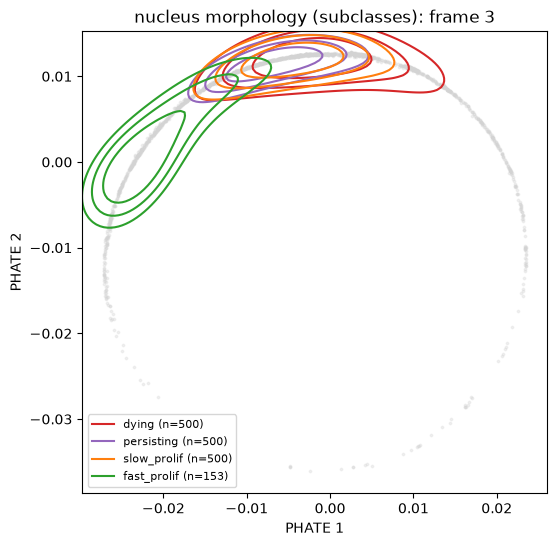

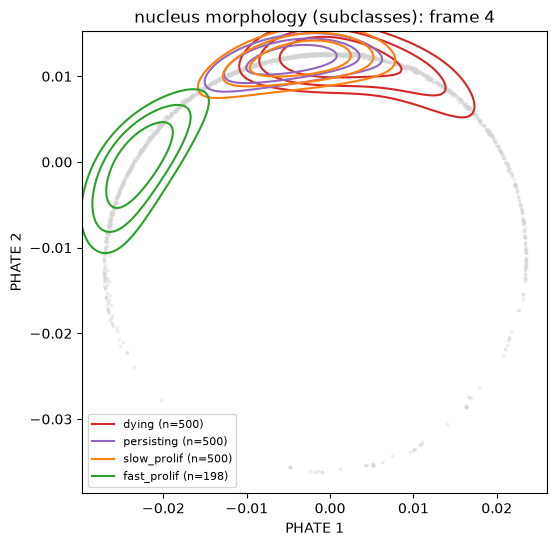

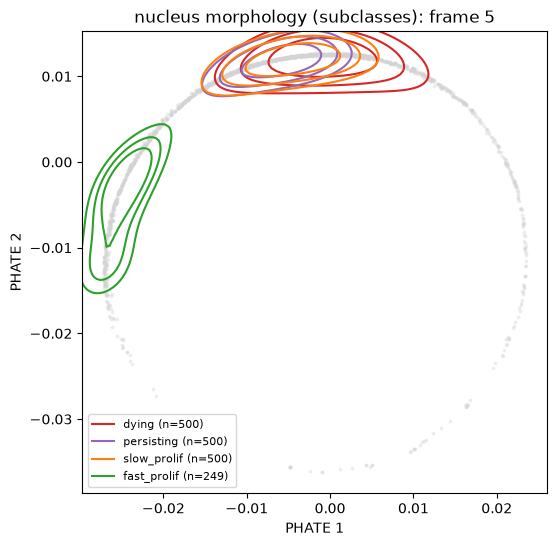

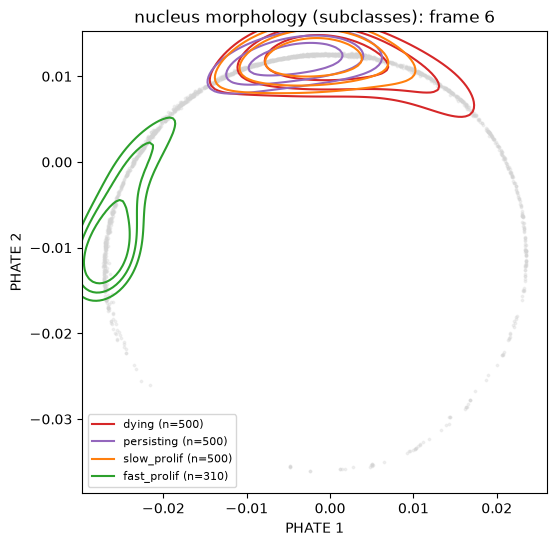

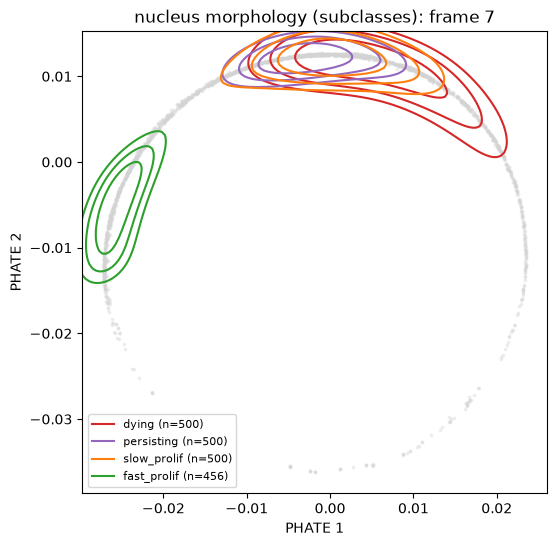

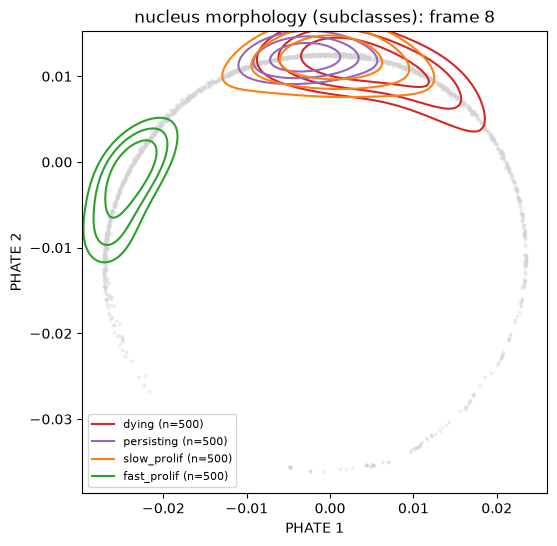

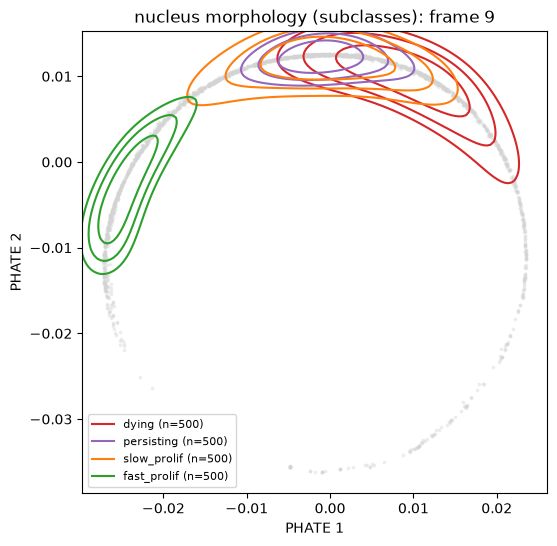

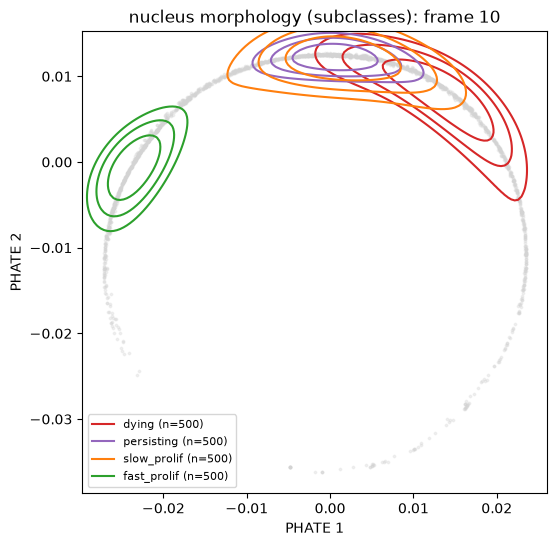

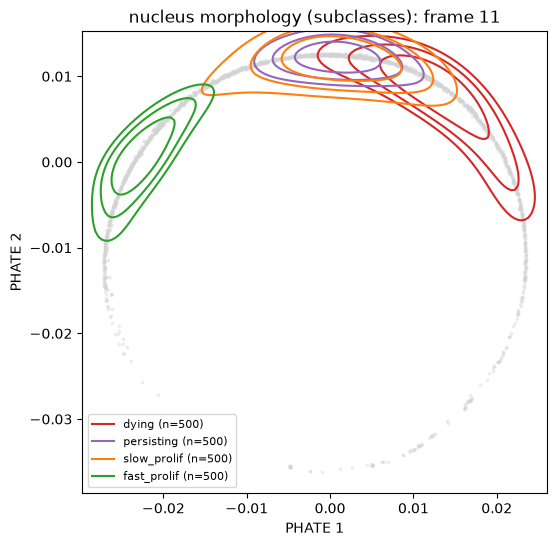

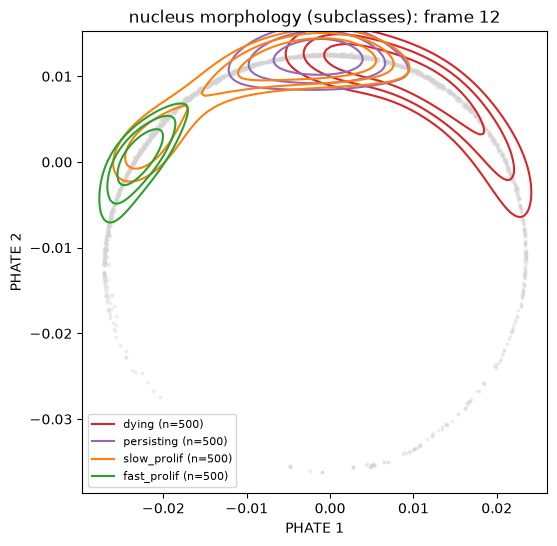

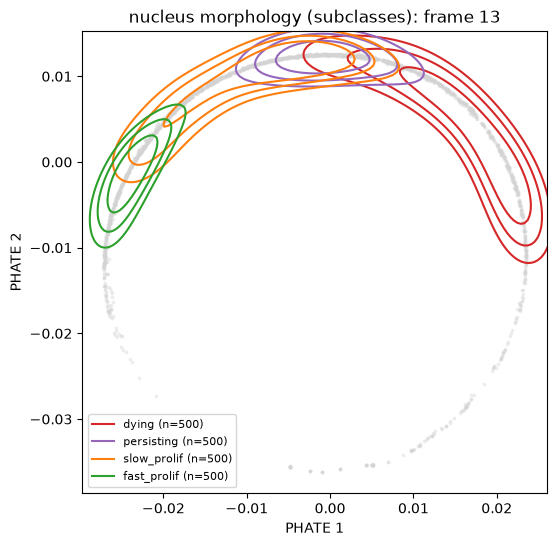

  Saved 13 frame(s) to /gpfs/projects/b1042/GoyalLab/sohini/drug_response_morphology/analyses/01_naive_vs_vem/output/plots/03_vem_subclasses_over_time/nuc_phate.pdf and /gpfs/projects/b1042/GoyalLab/sohini/drug_response_morphology/analyses/01_naive_vs_vem/output/plots/03_vem_subclasses_over_time/svgs


In [4]:
nuc_vem_dfs = process_modality('nuc')
